# iAmTime forecasting demo on Rossmann store sales

[iAmTime](https://arxiv.org/abs/2603.22586) is a time-series foundation model that accepts **in-context examples**: completed (history → future) demonstrations passed together with the series to forecast. This notebook is a second retail demo next to `iamtime_walmart_forecasting_demo.ipynb`, built on a different fev-bench dataset with **real promotions**. It keeps the same three-part format per section:

| Part | What you get |
|---|---|
| **Input card** | the exact array / dict shape passed to `predict_quantiles` |
| **Hero figure** | history → forecast fan (10–90 %) + median, observed future overlaid, and one **dashed reference line** = "what you would get without the feature" |
| **Honesty table** | the same comparison on many stores or forecast origins: mean / median MASE, win rate, paired bootstrap CI |

**Data.** `rossmann_1D` from [fev-bench](https://huggingface.co/spaces/autogluon/fev-bench): daily sales of 1,115 Rossmann drug stores in Germany, 2013-01-01 to 2015-07-31. fev-bench forecasts 48 days ahead with these known covariates: `Promo` (the store runs the chain's promotion that day), `Open`, `StateHoliday`, `SchoolHoliday` and `DayOfWeek`; `Customers` is past-only. Static attributes include `StoreType` (a–d) and `Assortment` (a = basic, b = extra, c = extended).

| § | Task | Reference line | What it shows |
|---|---|---|---|
| 1 | Univariate forecasting | seasonal naive (same weekday last week) | zero-shot 48-day forecasts for three stores in one batch |
| 2 | Multivariate forecasting | univariate forecast | sales and customer counts forecast jointly |
| 3 | Covariates and what-if scenarios | forecast without covariates | the store-open, holiday and promotion calendars are known in advance; promotion scenarios and a dose–response |
| 4 | Forecasting with examples (ICL) | zero-shot from the same short context | last year's Christmas from the store and its **sibling stores** (same type and assortment); a **new store** with 14 days of history |

Other fev-bench retail datasets that fit the same workflows: `favorita_stores_*` (Ecuador grocery, store × product family, with `onpromotion` and holidays), `m5_*` (Walmart item-level sales with prices and events), `rohlik_sales_*` (online grocery with prices and discount types), `rohlik_orders_*`, `hierarchical_sales_*`, `restaurant` (visitor counts) and `hermes` (fashion, weekly, with an external signal).

Checkpoint: [`anishsaha/iAmTime-base-forecast`](https://huggingface.co/anishsaha/iAmTime-base-forecast). Figures are saved to `docs/figures/` (relative to the notebook).

## Setup

Install the package with the notebook and training extras from the repository root (the `training` extra provides `datasets` and `pandas`):

```bash
pip install -e ".[notebook,training]"
```

The first run downloads the checkpoint and the dataset from the Hugging Face Hub and caches them locally.

In [1]:
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from matplotlib.ticker import FuncFormatter

from iAmTime.pipeline import iAmTimePipeline

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=3, suppress=True)

In [2]:
if torch.cuda.is_available():
    DEVICE = "cuda"
    TORCH_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
else:
    DEVICE = "cpu"
    TORCH_DTYPE = torch.float32

MODEL_ID = "anishsaha/iAmTime-base-forecast"

print(f"Device: {DEVICE}")
print(f"Dtype: {TORCH_DTYPE}")
print(f"Model: {MODEL_ID}")

Device: cpu
Dtype: torch.float32
Model: anishsaha/iAmTime-base-forecast


In [3]:
pipeline = iAmTimePipeline.from_pretrained(
    MODEL_ID,
    device_map=DEVICE,
    dtype=TORCH_DTYPE,
)
pipeline.model.eval()
print("Pipeline loaded successfully.")

Pipeline loaded successfully.


### Helpers: data, forecasts, evaluation, plots

Forecasts are scored with **MASE**: the mean absolute error of the median forecast divided by the in-sample mean absolute error of a seasonal naive forecast (same weekday one week earlier) on the context. Lower is better. Each section ends with a **scorecard**: mean and median MASE, the win rate against a reference variant, and a paired bootstrap 95 % CI on the mean difference.

In [4]:
DATASET_PATH = "autogluon/fev_datasets"
QUANTILE_LEVELS = [0.1, 0.5, 0.9]
COLORS = {"history": "#3f4652", "truth": "#23836b", "forecast": "#8f5fa2", "reference": "#d08c2e"}

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"rossmann_{name}.png", dpi=130, bbox_inches="tight")

def load_config(config):
    return load_dataset(DATASET_PATH, config, split="train").to_pandas()

def column_matrix(frame, column):
    matrix = np.stack([np.asarray(values, dtype=np.float64) for values in frame[column]])
    return pd.DataFrame(matrix.T).interpolate(limit_direction="both").to_numpy().T.astype(np.float32)

def predict(input_batch, horizon):
    quantiles, _ = pipeline.predict_quantiles(input_batch, prediction_length=horizon, quantile_levels=QUANTILE_LEVELS)
    return quantiles.detach().cpu().numpy() if isinstance(quantiles, torch.Tensor) else quantiles

def mase(history, truth, forecast, season):
    scale = np.mean(np.abs(history[season:] - history[:-season]))
    return float(np.mean(np.abs(truth - forecast)) / max(scale, 1e-6))

def seasonal_naive(history, horizon, season):
    return np.resize(history[-season:], horizon)

def scorecard(scores, reference, n_boot=2000, seed=0):
    # scores: DataFrame, one column per variant, one row per forecast, values = MASE.
    rng = np.random.default_rng(seed)
    n = len(scores)
    idx = rng.integers(0, n, size=(n_boot, n))
    ref = scores[reference].to_numpy()
    rows = []
    for name in scores.columns:
        s = scores[name].to_numpy()
        diff = s - ref
        mean_ci = np.percentile(s[idx].mean(axis=1), [2.5, 97.5])
        diff_ci = np.percentile(diff[idx].mean(axis=1), [2.5, 97.5])
        rows.append({
            "mean MASE": s.mean(), "mean 95% CI": f"[{mean_ci[0]:.3f}, {mean_ci[1]:.3f}]",
            "median MASE": np.median(s),
            "win rate vs ref": np.nan if name == reference else (s < ref).mean(),
            "Δ mean vs ref": diff.mean(), "Δ 95% CI": f"[{diff_ci[0]:.3f}, {diff_ci[1]:.3f}]",
        })
    table = pd.DataFrame(rows, index=scores.columns)
    table.index.name = f"reference: {reference}"
    return table.round(3)

def plot_ladder(scores, reference, title, name=None, n_boot=2000):
    # Horizontal bars of mean MASE with bootstrap CIs; the reference bar is grey.
    rng = np.random.default_rng(0)
    idx = rng.integers(0, len(scores), size=(n_boot, len(scores)))
    means = scores.mean()
    cis = np.stack([np.percentile(scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in scores.columns])
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(scores.columns) + 1.2))
    y = np.arange(len(scores.columns))[::-1]
    colors = ["#9a9a9a" if c == reference else COLORS["forecast"] for c in scores.columns]
    ax.barh(y, means, color=colors, height=0.6)
    ax.errorbar(means, y, xerr=[means - cis[:, 0], cis[:, 1] - means], fmt="none", ecolor="#333333", capsize=3, lw=1)
    ax.set_yticks(y, scores.columns)
    ax.set_xlabel(f"mean MASE over {len(scores)} forecasts (bootstrap 95% CI)")
    ax.set_title(title)
    ax.axvline(means[reference], color="#9a9a9a", lw=0.8, ls="--")
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

def plot_forecast(ax, history_x, history, future_x, truth, quantiles, title, reference=None, reference_label=None, ylabel=None):
    ax.plot(history_x, history, color=COLORS["history"], lw=1.1, label="History")
    ax.plot(future_x, truth, color=COLORS["truth"], lw=1.3, label="Observed future")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.20, label="10-90% interval")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.6, label="Median forecast")
    if reference is not None:
        ax.plot(future_x, reference, color=COLORS["reference"], lw=1.2, ls="--", label=reference_label)
    ax.axvline(future_x[0], color="#999999", lw=0.8, ls="--")
    ax.set_title(title)
    if ylabel:
        ax.set_ylabel(ylabel)

### Rossmann data

181 stores have a gap of about six months in 2014 (stores closed for refurbishment are missing from the data rather than recorded as zero). They are dropped, leaving 934 stores with complete daily histories. Closed days (mostly Sundays and public holidays) have zero sales. `StateHoliday` is a category (`0` none, `a` public holiday, `b` Easter, `c` Christmas); it is used as a 0/1 indicator.

In [5]:
HORIZON = 48       # Days, as in fev-bench.
CONTEXT = 364      # Days of history for Sections 1-3.
SEASON = 7

frame = load_config("rossmann_1D")
days = pd.DatetimeIndex(frame["timestamp"].iloc[0])
raw_sales = np.stack([np.asarray(values, dtype=np.float64) for values in frame["Sales"]])
complete = ~np.isnan(raw_sales).any(axis=1)
frame = frame[complete].reset_index(drop=True)

store_ids = frame["id"].astype(str).tolist()
sales = raw_sales[complete].astype(np.float32)
customers = column_matrix(frame, "Customers")
calendar = {
    "Open": column_matrix(frame, "Open"),
    "Promo": column_matrix(frame, "Promo"),
    "SchoolHoliday": column_matrix(frame, "SchoolHoliday"),
    "StateHoliday": np.stack([np.asarray(values).astype(str) != "0" for values in frame["StateHoliday"]]).astype(np.float32),
}
store_class = (frame["StoreType"].astype(str) + "/" + frame["Assortment"].astype(str)).to_numpy()
print(f"{len(store_ids)} complete stores (dropped {int((~complete).sum())}); {days[0].date()} to {days[-1].date()} ({len(days)} days)")
print("Stores per type/assortment:", pd.Series(store_class).value_counts().to_dict())

def row_of(store_id):
    return store_ids.index(str(store_id))

def describe(row):
    return f"Store {store_ids[row]} (type/assortment {store_class[row]})"

def sales_score(row, origin, forecast, context=CONTEXT):
    return mase(sales[row, origin - context:origin], sales[row, origin:origin + HORIZON], forecast, SEASON)

origin = len(days) - HORIZON
future_days = days[origin:origin + HORIZON]

934 complete stores (dropped 181); 2013-01-01 to 2015-07-31 (942 days)
Stores per type/assortment: {'a/a': 312, 'a/c': 205, 'd/c': 177, 'd/a': 90, 'c/a': 68, 'c/c': 66, 'b/b': 8, 'b/a': 7, 'b/c': 1}


## 1. Univariate forecasting

**Input card.** A two-dimensional array with shape `(batch, context)`:

```python
uni_input = sales[rows, origin - 364:origin]      # (3, 364): one year of daily sales
quantiles, _ = pipeline.predict_quantiles(uni_input, prediction_length=48, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (3, 48, 3)
```

Three stores of different types, forecast for the last 48 days of the data (2015-06-14 to 2015-07-31).

**How to read the figure.** Grey = the last 8 weeks of the context; purple = median forecast with the 10–90 % band; green = what actually happened; **dashed orange = seasonal naive** (the same weekday one week earlier). MASE of both in each title. The forecast has no calendar information here, so it cannot know which days are promotion days; Section 3 adds that.

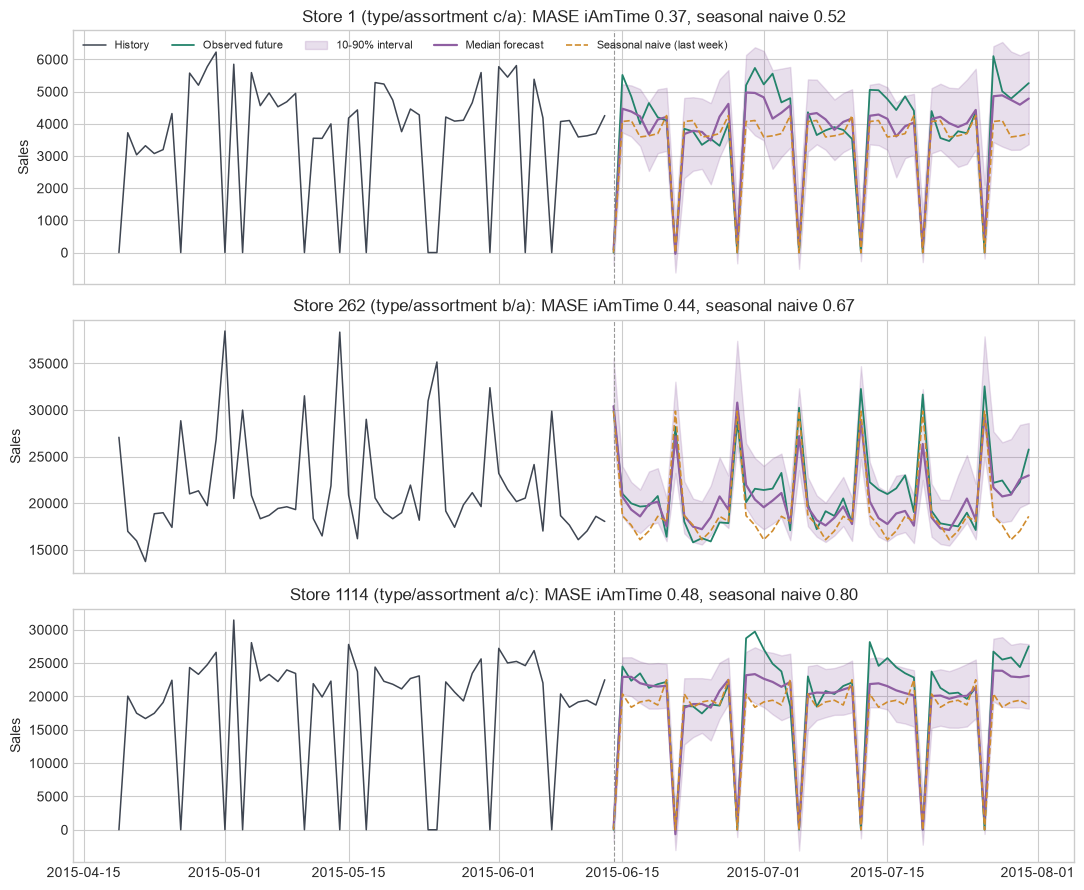

In [6]:
UNIVARIATE_STORES = ["1", "262", "1114"]

rows = [row_of(s) for s in UNIVARIATE_STORES]
uni_quantiles = predict(sales[rows, origin - CONTEXT:origin], HORIZON)

fig, axes = plt.subplots(len(rows), 1, figsize=(11, 3.0 * len(rows)), sharex=True)
for ax, row, quantiles in zip(axes, rows, uni_quantiles):
    context = sales[row, origin - CONTEXT:origin]
    truth = sales[row, origin:origin + HORIZON]
    naive = seasonal_naive(context, HORIZON, SEASON)
    plot_forecast(ax, days[origin - 56:origin], context[-56:], future_days, truth, quantiles,
                  f"{describe(row)}: MASE iAmTime {sales_score(row, origin, quantiles[:, 1]):.2f}, seasonal naive {sales_score(row, origin, naive):.2f}",
                  reference=naive, reference_label="Seasonal naive (last week)", ylabel="Sales")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "01_univariate")
plt.show()

### 1b. Scorecard: iAmTime vs. seasonal naive

64 random stores × 2 forecast origins (the last 48 days, and 13 weeks earlier), 128 forecasts.

In [7]:
rng = np.random.default_rng(0)
score_rows = rng.choice(len(store_ids), size=64, replace=False)
score_origins = [len(days) - HORIZON, len(days) - HORIZON - 91]
score_pairs = [(r, o) for r in score_rows for o in score_origins]
score_quantiles = predict(np.stack([sales[r, o - CONTEXT:o] for r, o in score_pairs]), HORIZON)

uni_scores = pd.DataFrame({
    "seasonal naive (last week)": [sales_score(r, o, seasonal_naive(sales[r, o - CONTEXT:o], HORIZON, SEASON)) for r, o in score_pairs],
    "iAmTime zero-shot": [sales_score(r, o, q[:, 1]) for (r, o), q in zip(score_pairs, score_quantiles)],
})
scorecard(uni_scores, reference="seasonal naive (last week)")

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: seasonal naive (last week),,,,,,
seasonal naive (last week),0.794,"[0.755, 0.839]",0.800,NaN,0.000,"[0.000, 0.000]"
iAmTime zero-shot,0.658,"[0.611, 0.704]",0.631,0.828,-0.136,"[-0.163, -0.111]"


**Result.** iAmTime beats the weekly seasonal naive forecast on 83 % of the 128 forecasts (mean MASE 0.66 vs 0.79). Both miss the promotion weeks, which neither can see without the calendar.

## 2. Multivariate forecasting: sales and customers

Sales and the number of customers move together: most of the daily variation in sales is variation in footfall. Forecasting both jointly lets each use the other's history.

**Input card.** A three-dimensional array with shape `(batch, variates, context)`:

```python
multi_input = np.stack([sales[row], customers[row]])[None, :, origin - 364:origin]   # (1, 2, 364)
quantiles, _ = pipeline.predict_quantiles(multi_input, prediction_length=48, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (1, 2, 48, 3)
```

**How to read the figure.** Store 1, last 48 days. Solid purple = joint forecast; **dashed orange = the same variable forecast on its own**.

Correlation of sales and customers over the context: 0.99


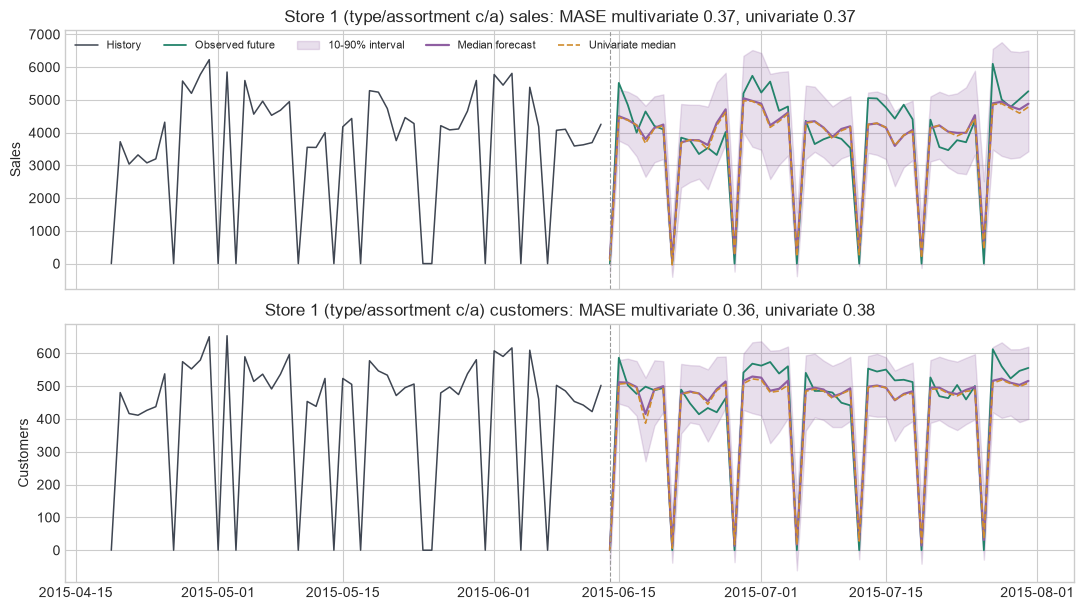

In [8]:
MULTI_STORE = "1"
row = row_of(MULTI_STORE)
multi_context = np.stack([sales[row, origin - CONTEXT:origin], customers[row, origin - CONTEXT:origin]])
print(f"Correlation of sales and customers over the context: {np.corrcoef(multi_context)[0, 1]:.2f}")
joint_quantiles = predict(multi_context[None], HORIZON)[0]
single_quantiles = predict(multi_context, HORIZON)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
for ax, name, values, joint, single in zip(axes, ["Sales", "Customers"], [sales, customers], joint_quantiles, single_quantiles):
    context = values[row, origin - CONTEXT:origin]
    truth = values[row, origin:origin + HORIZON]
    plot_forecast(ax, days[origin - 56:origin], context[-56:], future_days, truth, joint,
                  f"{describe(row)} {name.lower()}: MASE multivariate {mase(context, truth, joint[:, 1], SEASON):.2f}, univariate {mase(context, truth, single[:, 1], SEASON):.2f}",
                  reference=single[:, 1], reference_label="Univariate median", ylabel=name)
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "02_multivariate")
plt.show()

### 2b. Scorecard: joint vs. separate

The 128 store-origin pairs of 1b; scores for sales and for customers.

In [9]:
pair_contexts = np.stack([np.stack([sales[r, o - CONTEXT:o], customers[r, o - CONTEXT:o]]) for r, o in score_pairs])
pair_truths = np.stack([np.stack([sales[r, o:o + HORIZON], customers[r, o:o + HORIZON]]) for r, o in score_pairs])
joint = predict(pair_contexts, HORIZON)
separate = predict(pair_contexts.reshape(-1, CONTEXT), HORIZON).reshape(joint.shape)

flat = lambda a: a.reshape(-1, *a.shape[2:])
multi_scores = pd.DataFrame({
    "univariate (each variable alone)": [mase(h, y, q[:, 1], SEASON) for h, y, q in zip(flat(pair_contexts), flat(pair_truths), flat(separate))],
    "multivariate (joint)": [mase(h, y, q[:, 1], SEASON) for h, y, q in zip(flat(pair_contexts), flat(pair_truths), flat(joint))],
    "variable": ["Sales", "Customers"] * len(score_pairs),
})
print("Mean MASE per variable:")
print(multi_scores.groupby("variable").mean().round(3).T.to_string())
scorecard(multi_scores.drop(columns="variable"), reference="univariate (each variable alone)")

Mean MASE per variable:
variable                          Customers  Sales
univariate (each variable alone)      0.645  0.658
multivariate (joint)                  0.662  0.665


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: univariate (each variable alone),,,,,,
univariate (each variable alone),0.652,"[0.620, 0.683]",0.653,NaN,0.000,"[0.000, 0.000]"
multivariate (joint),0.663,"[0.631, 0.696]",0.671,0.293,0.012,"[0.007, 0.016]"


**Result.** Joint forecasting is slightly but consistently **worse** here (mean MASE 0.663 vs 0.652, a win on only 29 % of forecasts). Sales and customers are almost perfectly correlated (0.99 for store 1), so each series' own history already carries what the other could add, and the joint input only adds noise.

## 3. Covariates: store-open, holiday and promotion calendars

Retailers know their own calendar: which days a store will be open, which days are public or school holidays, and when the chain's promotion runs. These are genuine **known future covariates**.

**Input card.** A dictionary per store:

```python
{
    "target": sales[row, origin - 364:origin],                                            # (364,)
    "past_covariates":   {"Open": ..., "Promo": ..., "StateHoliday": ..., "SchoolHoliday": ...},   # each (364,)
    "future_covariates": {"Open": ..., "Promo": ..., "StateHoliday": ..., "SchoolHoliday": ...},   # each (48,)
}
```

**How to read the figure.** Store 1, last 48 days. Solid = forecast with the calendar, **dashed = without**. Below: promotion days (red) and closed days (grey) over the same period. Rossmann promotions run Monday to Friday in alternating weeks, and the sales level jumps on promotion days.

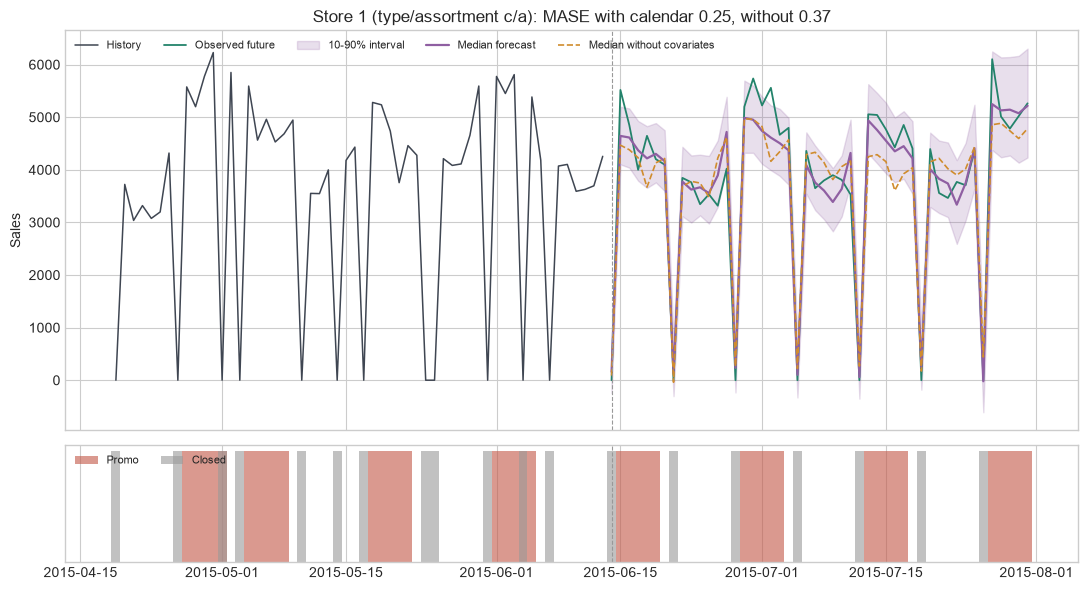

In [10]:
COVARIATE_STORE = "1"

def make_calendar_input(row, origin, names=tuple(calendar), promo=None):
    def window(name, start, stop):
        values = calendar[name][row] if name != "Promo" or promo is None else promo
        return values[start:stop]
    return {
        "target": sales[row, origin - CONTEXT:origin],
        "past_covariates": {name: window(name, origin - CONTEXT, origin) for name in names},
        "future_covariates": {name: window(name, origin, origin + HORIZON) for name in names},
    }

row = row_of(COVARIATE_STORE)
with_q, without_q = predict([make_calendar_input(row, origin), {"target": sales[row, origin - CONTEXT:origin]}], HORIZON)
context = sales[row, origin - CONTEXT:origin]
truth = sales[row, origin:origin + HORIZON]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.0), sharex=True, gridspec_kw={"height_ratios": [2.4, 0.7]})
plot_forecast(axes[0], days[origin - 56:origin], context[-56:], future_days, truth, with_q,
              f"{describe(row)}: MASE with calendar {sales_score(row, origin, with_q[:, 1]):.2f}, without {sales_score(row, origin, without_q[:, 1]):.2f}",
              reference=without_q[:, 1], reference_label="Median without covariates", ylabel="Sales")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
window = slice(origin - 56, origin + HORIZON)
axes[1].bar(days[window], calendar["Promo"][row, window], width=1.0, color="#c25645", alpha=0.6, label="Promo")
axes[1].bar(days[window], 1 - calendar["Open"][row, window], width=1.0, color="#999999", alpha=0.6, label="Closed")
axes[1].axvline(days[origin], color="#999999", lw=0.8, ls="--")
axes[1].set_yticks([])
axes[1].legend(ncol=2, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_calendar_covariates")
plt.show()

### 3a. Scorecard: which covariates matter?

The 128 store-origin pairs of 1b, with three inputs: no covariates, only the open/holiday calendar, and the full calendar including promotions.

In [11]:
covariate_variants = {
    "no covariates": lambda r, o: {"target": sales[r, o - CONTEXT:o]},
    "Open + holidays": lambda r, o: make_calendar_input(r, o, names=("Open", "StateHoliday", "SchoolHoliday")),
    "Open + holidays + Promo": lambda r, o: make_calendar_input(r, o),
}
covariate_scores = pd.DataFrame({
    name: [sales_score(r, o, q[:, 1]) for (r, o), q in zip(score_pairs, predict([build(r, o) for r, o in score_pairs], HORIZON))]
    for name, build in covariate_variants.items()
})
scorecard(covariate_scores, reference="no covariates")

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: no covariates,,,,,,
no covariates,0.658,"[0.611, 0.704]",0.631,NaN,0.000,"[0.000, 0.000]"
Open + holidays,0.554,"[0.535, 0.575]",0.541,0.516,-0.104,"[-0.139, -0.072]"
Open + holidays + Promo,0.375,"[0.353, 0.402]",0.341,0.969,-0.282,"[-0.322, -0.244]"


**Result.** The calendars are the biggest single improvement in this notebook. The open/holiday calendar alone lowers the mean MASE from 0.66 to 0.55 by placing closed days correctly; adding the promotion calendar brings it to 0.38, better on 97 % of forecasts. For store 1, a promotion day adds about a quarter to the day's sales (Section 3c), and the promotion calendar is known in advance.

### 3b. What-if: promotion calendars

Because future covariates are inputs, a promotion plan is just another row in the batch. For store 1 the future `Promo` calendar is replaced by plans that promote on the open weekdays of the first `n` weeks of the horizon, for `n = 0, 1, …, 6`; the open/holiday calendar stays as it is. Only the actual plan has an observed outcome; the others are counterfactuals.

**How to read the figure.** Median forecasts for a few plans; the shaded weeks are the promotion weeks of the 3-week plan.

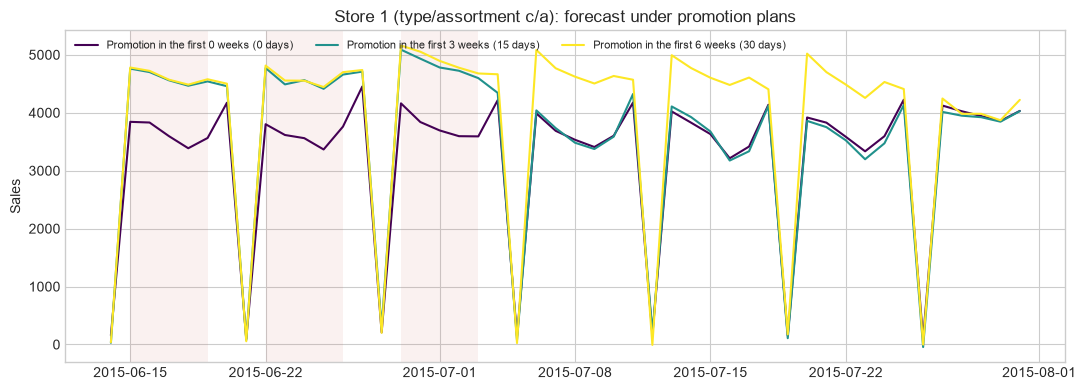

In [12]:
PROMO_WEEKS = list(range(0, 7))
row = row_of(COVARIATE_STORE)
open_future = calendar["Open"][row, origin:origin + HORIZON]
weekday_future = np.asarray(future_days.dayofweek < 5, dtype=np.float32)

def promo_plan(weeks):
    promo = calendar["Promo"][row].copy()
    plan = np.zeros(HORIZON, dtype=np.float32)
    plan[:7 * weeks] = 1.0
    promo[origin:origin + HORIZON] = plan * weekday_future * open_future
    return promo

plans = [promo_plan(w) for w in PROMO_WEEKS]
plan_quantiles = predict([make_calendar_input(row, origin, promo=p) for p in plans], HORIZON)
promo_days = [int(p[origin:origin + HORIZON].sum()) for p in plans]

fig, ax = plt.subplots(figsize=(11, 4))
cmap = plt.get_cmap("viridis")
for k, w in enumerate([0, 3, 6]):
    ax.plot(future_days, plan_quantiles[w][:, 1], color=cmap(k / 2), lw=1.5, label=f"Promotion in the first {w} weeks ({promo_days[w]} days)")
promo3 = plans[3][origin:origin + HORIZON] > 0
ax.fill_between(future_days, 0, 1, where=promo3, transform=ax.get_xaxis_transform(), color="#c25645", alpha=0.08, lw=0)
ax.set_ylabel("Sales")
ax.set_title(f"{describe(row)}: forecast under promotion plans")
ax.legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_promo_scenarios")
plt.show()

### 3c. Dose–response: promotion days vs. sales

x-axis: number of promotion days in the horizon; y-axis: predicted extra sales over the 48 days relative to the no-promotion plan. The dashed line is the historical promotion effect in the same store's 1-year context: the average sales on open promotion days minus open non-promotion days, matched by weekday, times the number of promotion days. Agreement means the model's sensitivity to promotions matches what the store's own history shows.

Historical promotion uplift: 1,210 per promotion day; model: 1,124 per promotion day


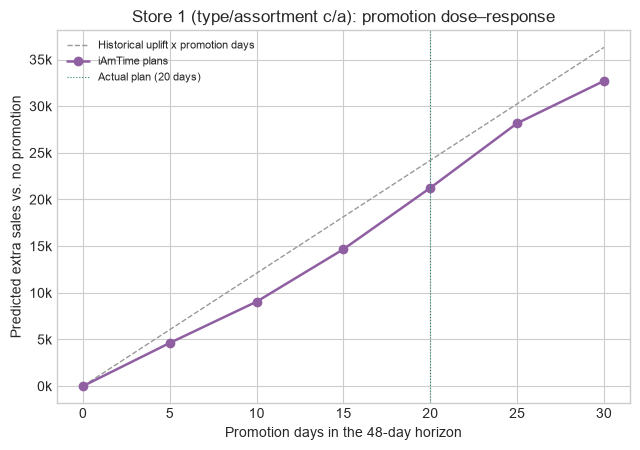

In [13]:
base = plan_quantiles[0][:, 1].sum()
predicted_extra = [q[:, 1].sum() - base for q in plan_quantiles]

ctx = slice(origin - CONTEXT, origin)
ctx_sales, ctx_open, ctx_promo = sales[row, ctx], calendar["Open"][row, ctx] > 0, calendar["Promo"][row, ctx] > 0
ctx_weekday = days[ctx].dayofweek
uplifts = [ctx_sales[ctx_open & ctx_promo & (ctx_weekday == d)].mean() - ctx_sales[ctx_open & ~ctx_promo & (ctx_weekday == d)].mean() for d in range(5)]
historical_uplift = float(np.nanmean(uplifts))
print(f"Historical promotion uplift: {historical_uplift:,.0f} per promotion day; "
      f"model: {np.polyfit(promo_days, predicted_extra, 1)[0]:,.0f} per promotion day")

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot(promo_days, [historical_uplift * d for d in promo_days], color="#999999", lw=1.0, ls="--", label="Historical uplift x promotion days")
ax.plot(promo_days, predicted_extra, "o-", color=COLORS["forecast"], lw=1.8, label="iAmTime plans")
actual_days = int(calendar["Promo"][row, origin:origin + HORIZON].sum())
ax.axvline(actual_days, color=COLORS["truth"], lw=0.8, ls=":", label=f"Actual plan ({actual_days} days)")
ax.set_xlabel("Promotion days in the 48-day horizon")
ax.set_ylabel("Predicted extra sales vs. no promotion")
ax.set_title(f"{describe(row)}: promotion dose–response")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
savefig(fig, "03_dose_response")
plt.show()

**Result.** The predicted extra sales grow almost linearly with the number of promotion days, about 1,120 per promotion day against 1,210 per day in the store's own history: the model's promotion response matches what the store's past promotions show, slightly conservatively. Only the actual plan (20 days) has an observed outcome; the others are counterfactuals.

## 4. Forecasting with examples: Christmas and new stores

The full ICL input supplies completed **support examples** before the query. Each example has a target history and its observed future; the model treats them as demonstrations of how series like the query behave, without fine-tuning.

**Input card.**

```python
{
    "example_target_histories": [hist_1, ..., hist_k],   # each (56,)  completed demonstrations
    "example_target_futures":   [fut_1,  ..., fut_k],    # each (48,)
    "query_target_history":     hist_q,                  # (56,)       the store to forecast
}
```

**Design.** The query sees only its last **56 days**. Each example is the **same calendar window one year earlier** (shifted by 364 days, which keeps weekdays aligned) from:

- the query store itself, and
- **sibling stores**: stores with the same `StoreType` and `Assortment`, ranked by how closely their sales one year earlier matched the query store's own sales over the same window (z-normalised shape).

Everything ends before the query's forecast origin, so there is no leakage. Covariates are not used in this section, so the examples are the only source of calendar information.

| § | Question | Format |
|---|---|---|
| 4a | What does one forecast look like? | Christmas 2014 for one store |
| 4b | What does the model actually see? | prompt-anatomy figure |
| 4c | Do examples help around Christmas, and which ones? | scorecard on 260 forecasts + ladder with a shuffled-futures **control**; the same variants year-round |
| 4d | New store | 14 days of history and examples from sibling stores |
| 4e | How does the error change with the number of examples? | k-shot curve for the new-store case, k = 0 to 12 |

In [14]:
ICL_CONTEXT = 56
YEAR = 364

def season_profile(row, origin):
    window = sales[row, origin - YEAR:origin - YEAR + HORIZON]
    return (window - window.mean()) / max(window.std(), 1e-6)

def siblings(row, origin, count):
    candidates = np.flatnonzero(store_class == store_class[row])
    candidates = candidates[candidates != row]
    distances = np.linalg.norm(np.stack([season_profile(c, origin) for c in candidates]) - season_profile(row, origin), axis=1)
    return list(candidates[np.argsort(distances)[:count]])

def random_other_class(row, origin, count):
    candidates = np.flatnonzero(store_class != store_class[row])
    return list(np.random.default_rng(7 * row + origin).choice(candidates, size=count, replace=False))

def make_example_input(row, origin, sources, query_context=ICL_CONTEXT, example_context=ICL_CONTEXT, shuffle_futures=False):
    query = sales[row, origin - query_context:origin]
    if not sources:
        return {"query_target_history": query}
    futures = [sales[s, origin - YEAR:origin - YEAR + HORIZON] for s in sources]
    if shuffle_futures:
        futures = futures[1:] + futures[:1]  # Every history gets another example's future.
    return {
        "example_target_histories": [sales[s, origin - YEAR - example_context:origin - YEAR] for s in sources],
        "example_target_futures": futures,
        "query_target_history": query,
    }

### 4a. Christmas 2014

The query is store 1 from 2014-12-01: the 48-day horizon contains the Christmas peak, the closed public holidays and the January drop. The 56-day context (October–November) contains none of these. The examples are the same window in 2013 for store 1 and its 4 closest siblings.

Examples from stores: 1, 857, 843, 1059, 114


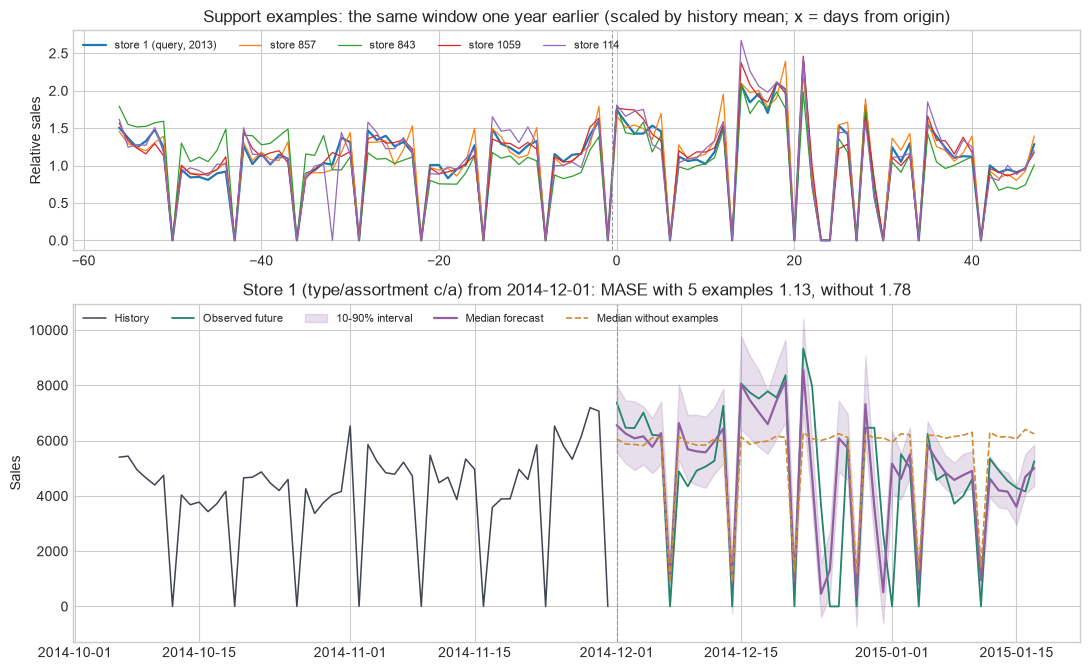

In [15]:
HERO_STORE = "1"
HERO_ORIGIN = pd.Timestamp("2014-12-01")

hero_row = row_of(HERO_STORE)
hero_origin = int(np.flatnonzero(days == HERO_ORIGIN)[0])
hero_sources = [hero_row, *siblings(hero_row, hero_origin, 4)]
print("Examples from stores:", ", ".join(store_ids[s] for s in hero_sources))
example_q, zero_q = predict([make_example_input(hero_row, hero_origin, hero_sources), make_example_input(hero_row, hero_origin, [])], HORIZON)
hero_context = sales[hero_row, hero_origin - ICL_CONTEXT:hero_origin]
hero_truth = sales[hero_row, hero_origin:hero_origin + HORIZON]
hero_future_days = days[hero_origin:hero_origin + HORIZON]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.8), gridspec_kw={"height_ratios": [1.3, 2.0]})
for s in hero_sources:
    window = sales[s, hero_origin - YEAR - ICL_CONTEXT:hero_origin - YEAR + HORIZON]
    axes[0].plot(np.arange(-ICL_CONTEXT, HORIZON), window / window[:ICL_CONTEXT].mean(), lw=1.6 if s == hero_row else 0.9,
                 label=f"store {store_ids[s]}" + (" (query, 2013)" if s == hero_row else ""))
axes[0].axvline(-0.5, color="#999999", lw=0.8, ls="--")
axes[0].set_title("Support examples: the same window one year earlier (scaled by history mean; x = days from origin)")
axes[0].set_ylabel("Relative sales")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plot_forecast(axes[1], days[hero_origin - ICL_CONTEXT:hero_origin], hero_context, hero_future_days, hero_truth, example_q,
              f"{describe(hero_row)} from {HERO_ORIGIN.date()}: MASE with 5 examples {sales_score(hero_row, hero_origin, example_q[:, 1], ICL_CONTEXT):.2f}, "
              f"without {sales_score(hero_row, hero_origin, zero_q[:, 1], ICL_CONTEXT):.2f}",
              reference=zero_q[:, 1], reference_label="Median without examples", ylabel="Sales")
axes[1].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "04a_christmas")
plt.show()

### 4b. Prompt anatomy: what the model actually sees

The same input as 4a, drawn the way the model receives it: five completed examples (history → observed future), then the query (history → **?**). The x-axis is days from each block's forecast origin.

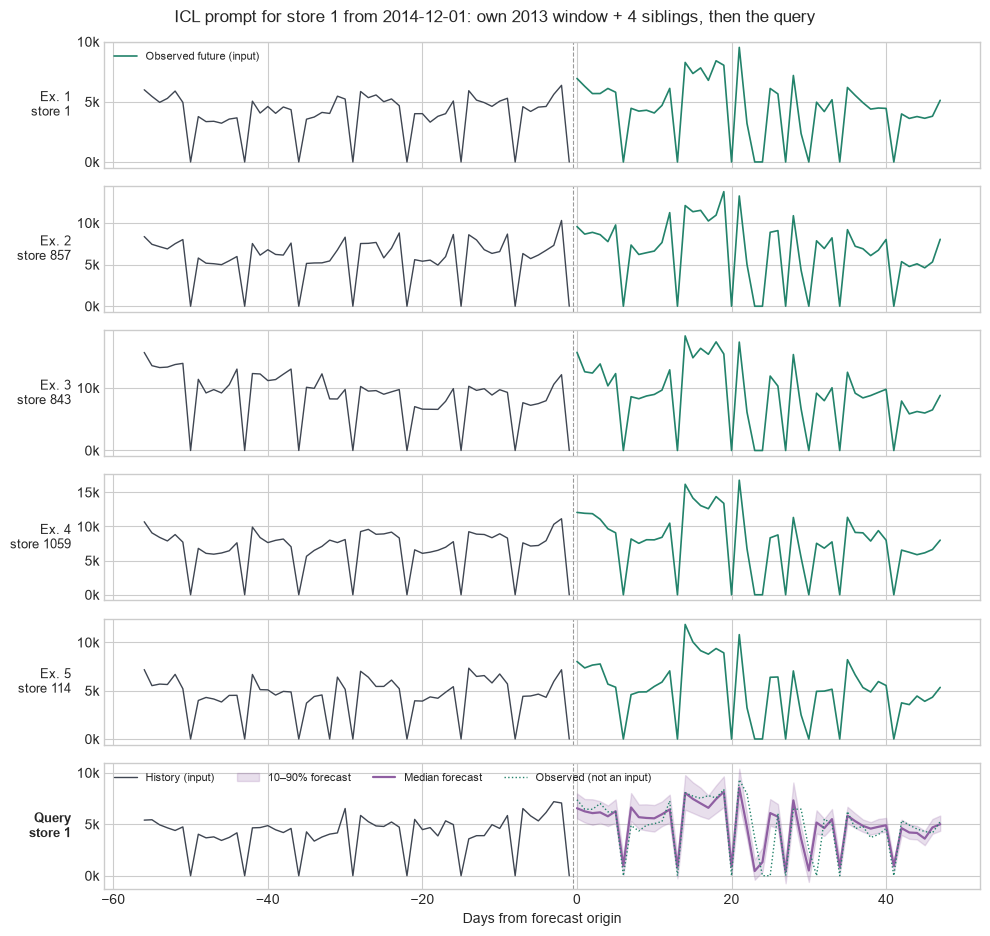

In [16]:
def plot_prompt_anatomy(row, origin, sources, quantiles, title, name=None, query_context=ICL_CONTEXT, example_context=ICL_CONTEXT):
    rows = len(sources) + 1
    fig, axes = plt.subplots(rows, 1, figsize=(10, 1.45 * rows + 0.8), sharex=True)
    future_x = np.arange(0, HORIZON)
    for k, (ax, s) in enumerate(zip(axes, sources)):
        ax.plot(np.arange(-example_context, 0), sales[s, origin - YEAR - example_context:origin - YEAR], color=COLORS["history"], lw=1.0)
        ax.plot(future_x, sales[s, origin - YEAR:origin - YEAR + HORIZON], color=COLORS["truth"], lw=1.2)
        ax.set_ylabel(f"Ex. {k + 1}\nstore {store_ids[s]}", rotation=0, ha="right", va="center", fontsize=9)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
    ax = axes[-1]
    ax.plot(np.arange(-query_context, 0), sales[row, origin - query_context:origin], color=COLORS["history"], lw=1.0, label="History (input)")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.2, label="10–90% forecast")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.6, label="Median forecast")
    ax.plot(future_x, sales[row, origin:origin + HORIZON], color=COLORS["truth"], lw=1.0, ls=":", label="Observed (not an input)")
    ax.set_ylabel(f"Query\nstore {store_ids[row]}", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
    ax.legend(ncol=4, frameon=False, loc="upper left", fontsize=8)
    ax.set_xlabel("Days from forecast origin")
    for ax in axes:
        ax.axvline(-0.5, color="#999999", lw=0.8, ls="--")
    axes[0].plot([], [], color=COLORS["truth"], lw=1.2, label="Observed future (input)")
    axes[0].legend(frameon=False, loc="upper left", fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

plot_prompt_anatomy(hero_row, hero_origin, hero_sources, example_q,
                    f"ICL prompt for store {HERO_STORE} from {HERO_ORIGIN.date()}: own 2013 window + 4 siblings, then the query", name="04b_prompt_anatomy")

### 4c. Scorecard: do examples help, and which ones?

**Around Christmas**: 52 random stores × 5 weekly origins from 2014-11-10 to 2014-12-08 (260 forecasts), so every horizon contains Christmas. Variants:

- zero-shot from the same 56 days (the **reference**),
- 1 example: the store itself one year earlier,
- 5 examples: the store and its 4 closest siblings,
- 5 sibling examples without the store's own past,
- the store plus 4 random stores of **other** types and assortments,
- **control**: the store + 4 siblings with their futures rotated, so every history is paired with another example's future. If this control were as good as the real examples, the benefit would be "more context", not in-context learning.

The second table repeats the main variants **year-round** (256 random store-origin pairs from 2014-03 to 2015-06), to show how much of the benefit is specific to the holiday season.

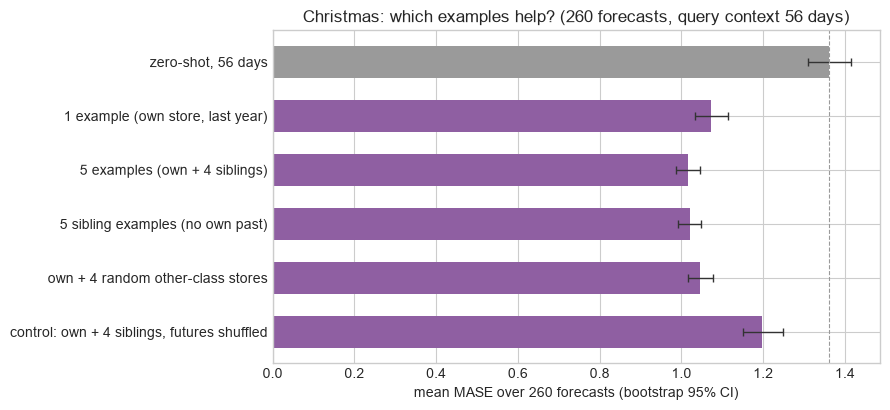

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 56 days",,,,,,
"zero-shot, 56 days",1.360,"[1.309, 1.415]",1.277,NaN,0.000,"[0.000, 0.000]"
"1 example (own store, last year)",1.072,"[1.033, 1.113]",1.017,0.969,-0.288,"[-0.329, -0.250]"
5 examples (own + 4 siblings),1.016,"[0.988, 1.046]",0.965,0.992,-0.343,"[-0.377, -0.313]"
5 sibling examples (no own past),1.020,"[0.991, 1.049]",0.982,0.988,-0.340,"[-0.372, -0.310]"
own + 4 random other-class stores,1.045,"[1.016, 1.076]",1.010,0.962,-0.315,"[-0.348, -0.284]"
"control: own + 4 siblings, futures shuffled",1.197,"[1.150, 1.248]",1.083,0.792,-0.163,"[-0.205, -0.119]"


In [17]:
rng = np.random.default_rng(1)
christmas_origins = [int(np.flatnonzero(days == pd.Timestamp(d))[0]) for d in ["2014-11-10", "2014-11-17", "2014-11-24", "2014-12-01", "2014-12-08"]]
christmas_pairs = [(r, o) for r in rng.choice(len(store_ids), size=52, replace=False) for o in christmas_origins]

def run_variants(pairs, variants, context=ICL_CONTEXT):
    return pd.DataFrame({
        name: [sales_score(r, o, q[:, 1], context) for (r, o), q in zip(pairs, predict([build(r, o) for r, o in pairs], HORIZON))]
        for name, build in variants.items()
    })

ICL_VARIANTS = {
    "zero-shot, 56 days": lambda r, o: make_example_input(r, o, []),
    "1 example (own store, last year)": lambda r, o: make_example_input(r, o, [r]),
    "5 examples (own + 4 siblings)": lambda r, o: make_example_input(r, o, [r, *siblings(r, o, 4)]),
    "5 sibling examples (no own past)": lambda r, o: make_example_input(r, o, siblings(r, o, 5)),
    "own + 4 random other-class stores": lambda r, o: make_example_input(r, o, [r, *random_other_class(r, o, 4)]),
    "control: own + 4 siblings, futures shuffled": lambda r, o: make_example_input(r, o, [r, *siblings(r, o, 4)], shuffle_futures=True),
}
REFERENCE = "zero-shot, 56 days"
christmas_results = run_variants(christmas_pairs, ICL_VARIANTS)
plot_ladder(christmas_results, REFERENCE, f"Christmas: which examples help? ({len(christmas_results)} forecasts, query context 56 days)", name="04c_christmas_ladder")
scorecard(christmas_results, reference=REFERENCE)

**Result (Christmas).** Every example variant beats zero-shot by a wide margin and on almost every forecast (mean MASE about 1.02 vs 1.36 for the store + 4 siblings, win rate 99 %). The store's own last year already gives most of the gain; siblings add a little, and 5 siblings without the store's own past are as good as with it. Random stores of other types are slightly worse than siblings. The shuffled-futures control is clearly worse than the real examples (1.20) but still better than zero-shot: the examples' futures all contain the same Christmas pattern, so even mismatched pairs still tell the model a holiday peak is coming.

In [18]:
all_origins = list(range(YEAR + ICL_CONTEXT, len(days) - HORIZON, 7))
all_pairs = [(r, o) for r in range(len(store_ids)) for o in all_origins]
year_round_pairs = [all_pairs[k] for k in np.random.default_rng(0).choice(len(all_pairs), size=256, replace=False)]
print(f"Year-round origins: {days[all_origins[0]].date()} to {days[all_origins[-1]].date()}")
year_round_results = run_variants(year_round_pairs, {name: ICL_VARIANTS[name] for name in [REFERENCE, "1 example (own store, last year)", "5 examples (own + 4 siblings)", "control: own + 4 siblings, futures shuffled"]})
scorecard(year_round_results, reference=REFERENCE)

Year-round origins: 2014-02-25 to 2015-06-09


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 56 days",,,,,,
"zero-shot, 56 days",0.713,"[0.673, 0.754]",0.609,NaN,0.000,"[0.000, 0.000]"
"1 example (own store, last year)",0.784,"[0.718, 0.881]",0.691,0.434,0.071,"[0.008, 0.174]"
5 examples (own + 4 siblings),0.731,"[0.694, 0.770]",0.671,0.484,0.019,"[-0.013, 0.049]"
"control: own + 4 siblings, futures shuffled",0.876,"[0.827, 0.927]",0.812,0.301,0.163,"[0.120, 0.207]"


**Result (year-round).** Away from the holidays the examples do not help: the store + 4 siblings is level with zero-shot (the CI on the difference includes 0) and the store's own last year alone is slightly worse. 56 days of history already show the weekly cycle and the alternating promotion weeks; the examples only pay off when the horizon holds something the context cannot show.

### 4d. New store: 14 days of history

A newly opened store has two weeks of sales and no own past year. Its sibling stores (same type and assortment) have full histories, and that is exactly what examples are for.

- **Query**: the last `COLD_CONTEXT = 14` days before the origin.
- **Examples**: 5 sibling stores, each as the matching 14-day window one year earlier and the following 48 days. Because a new store has no sales one year earlier, siblings are ranked here by the shape of their **last 14 days** against the query's.
- The query store's own past is **not** used.

The figure uses store 1 from 2014-12-01 again; the scorecard uses the 256 year-round store-origin pairs of 4c.

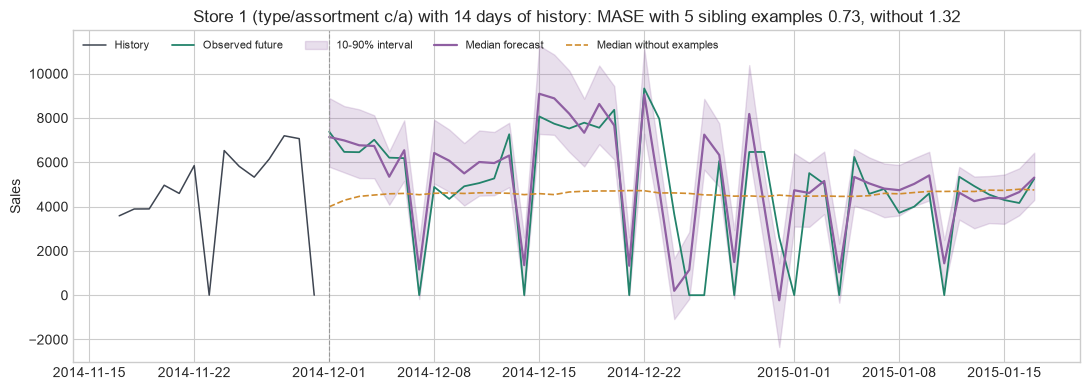

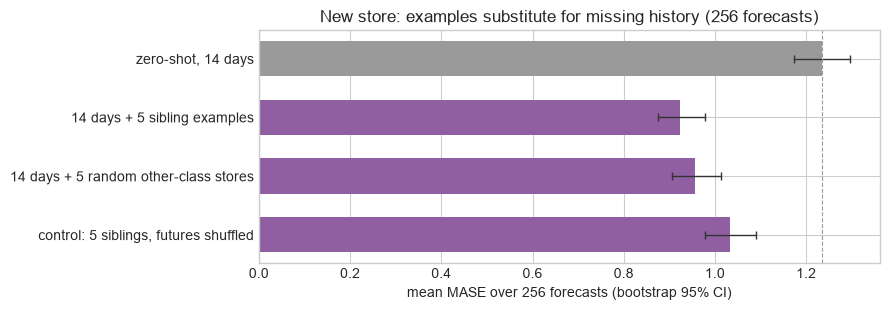

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 14 days",,,,,,
"zero-shot, 14 days",1.234,"[1.174, 1.297]",1.116,NaN,0.000,"[0.000, 0.000]"
14 days + 5 sibling examples,0.924,"[0.876, 0.979]",0.857,0.895,-0.310,"[-0.346, -0.275]"
14 days + 5 random other-class stores,0.957,"[0.906, 1.014]",0.851,0.883,-0.277,"[-0.311, -0.244]"
"control: 5 siblings, futures shuffled",1.033,"[0.977, 1.091]",0.952,0.758,-0.201,"[-0.242, -0.162]"


In [19]:
COLD_CONTEXT = 14

def recent_siblings(row, origin, count, same_class=True):
    mask = (store_class == store_class[row]) if same_class else (store_class != store_class[row])
    candidates = np.flatnonzero(mask)
    candidates = candidates[candidates != row]
    if not same_class:
        return list(np.random.default_rng(7 * row + origin).choice(candidates, size=count, replace=False))
    z = lambda w: (w - w.mean()) / max(w.std(), 1e-6)
    distances = np.linalg.norm(np.stack([z(sales[c, origin - COLD_CONTEXT:origin]) for c in candidates]) - z(sales[row, origin - COLD_CONTEXT:origin]), axis=1)
    return list(candidates[np.argsort(distances)[:count]])

def make_cold_input(row, origin, sources, shuffle_futures=False):
    return make_example_input(row, origin, sources, query_context=COLD_CONTEXT, example_context=COLD_CONTEXT, shuffle_futures=shuffle_futures)

cold_q, cold_zero_q = predict([make_cold_input(hero_row, hero_origin, recent_siblings(hero_row, hero_origin, 5)), make_cold_input(hero_row, hero_origin, [])], HORIZON)
fig, ax = plt.subplots(figsize=(11, 4))
plot_forecast(ax, days[hero_origin - COLD_CONTEXT:hero_origin], sales[hero_row, hero_origin - COLD_CONTEXT:hero_origin], hero_future_days, hero_truth, cold_q,
              f"{describe(hero_row)} with 14 days of history: MASE with 5 sibling examples {sales_score(hero_row, hero_origin, cold_q[:, 1], COLD_CONTEXT):.2f}, "
              f"without {sales_score(hero_row, hero_origin, cold_zero_q[:, 1], COLD_CONTEXT):.2f}",
              reference=cold_zero_q[:, 1], reference_label="Median without examples", ylabel="Sales")
ax.legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "04d_new_store")
plt.show()

cold_results = run_variants(year_round_pairs, {
    "zero-shot, 14 days": lambda r, o: make_cold_input(r, o, []),
    "14 days + 5 sibling examples": lambda r, o: make_cold_input(r, o, recent_siblings(r, o, 5)),
    "14 days + 5 random other-class stores": lambda r, o: make_cold_input(r, o, recent_siblings(r, o, 5, same_class=False)),
    "control: 5 siblings, futures shuffled": lambda r, o: make_cold_input(r, o, recent_siblings(r, o, 5), shuffle_futures=True),
}, context=COLD_CONTEXT)
plot_ladder(cold_results, "zero-shot, 14 days", f"New store: examples substitute for missing history ({len(cold_results)} forecasts)", name="04d_new_store_ladder")
scorecard(cold_results, reference="zero-shot, 14 days")

**Result.** With only 14 days of history, five sibling stores cut the mean MASE from 1.23 to 0.92 and win on 90 % of forecasts. Random stores of other types help almost as much (0.96): for a two-week-old store, any complete demonstration of how a Rossmann store's sales evolve over 48 days (weekly closures, promotion cycles, holidays) is valuable. The shuffled control is again worse than real siblings but better than nothing, because sibling futures resemble each other.

### 4e. Error vs. number of examples

The k-shot curve for the new-store case on the same 256 forecasts: the `k` closest sibling stores, for `k = 0, 1, 2, 3, 5, 8, 10, 12`. The checkpoint was trained with up to 6 examples; the shaded region (`k > 6`) is beyond that, and the model accepts it without changes.

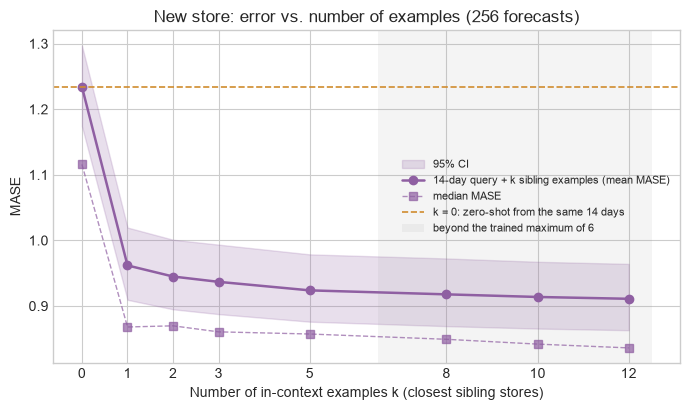

          k=0    k=1    k=2    k=3    k=5    k=8   k=10   k=12
mean    1.234  0.962  0.945  0.937  0.924  0.918  0.914  0.911
median  1.116  0.868  0.870  0.861  0.857  0.849  0.842  0.836


In [20]:
EXAMPLE_COUNTS = [0, 1, 2, 3, 5, 8, 10, 12]
TRAINED_MAX_EXAMPLES = 6

curve_scores = run_variants(year_round_pairs, {f"k={k}": (lambda k: lambda r, o: make_cold_input(r, o, recent_siblings(r, o, k) if k else []))(k) for k in EXAMPLE_COUNTS}, context=COLD_CONTEXT)
rng = np.random.default_rng(0)
idx = rng.integers(0, len(curve_scores), size=(2000, len(curve_scores)))
curve_mean = curve_scores.mean()
curve_ci = np.stack([np.percentile(curve_scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in curve_scores.columns])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(EXAMPLE_COUNTS, curve_ci[:, 0], curve_ci[:, 1], color=COLORS["forecast"], alpha=0.2, label="95% CI")
ax.plot(EXAMPLE_COUNTS, curve_mean, "o-", color=COLORS["forecast"], lw=1.8, label="14-day query + k sibling examples (mean MASE)")
ax.plot(EXAMPLE_COUNTS, curve_scores.median(), "s--", color=COLORS["forecast"], lw=1.0, alpha=0.7, label="median MASE")
ax.axhline(curve_mean.iloc[0], color=COLORS["reference"], lw=1.2, ls="--", label="k = 0: zero-shot from the same 14 days")
ax.axvspan(TRAINED_MAX_EXAMPLES + 0.5, EXAMPLE_COUNTS[-1] + 0.5, color="#999999", alpha=0.10, lw=0, label="beyond the trained maximum of 6")
ax.set_xticks(EXAMPLE_COUNTS)
ax.set_xlabel("Number of in-context examples k (closest sibling stores)")
ax.set_ylabel("MASE")
ax.set_title(f"New store: error vs. number of examples ({len(curve_scores)} forecasts)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
savefig(fig, "04e_example_count_curve")
plt.show()
print(pd.DataFrame({"mean": curve_mean, "median": curve_scores.median()}).round(3).T.to_string())

**Result.** The first sibling gives most of the gain (mean MASE 1.23 → 0.96); after that the error keeps falling slowly up to 12 examples. Going beyond the trained maximum of 6 continues to help a little and does not break the model.

## Summary

| § | What was shown | Reference |
|---|---|---|
| 1 | Zero-shot 48-day store forecasts in one batch | seasonal naive (last week) |
| 2 | Joint forecast of sales and customers | each variable alone |
| 3 | Open, holiday and promotion calendars as known covariates; promotion plans as what-if scenarios; promotion dose–response | without covariates; the store's historical promotion uplift |
| 4 | Last year's Christmas from the store and sibling stores; shuffled-futures control; year-round comparison; new store with 14 days of history; k-shot curve | zero-shot from the same short context |

Takeaways on this data: the known calendars (open days, holidays and especially promotions) are by far the most valuable input, and the model's promotion response matches each store's history; joint sales–customer forecasting does not help; and examples from the store's own past and sibling stores pay off when the horizon contains something the short context cannot show (Christmas) or when the store is new, but not on ordinary weeks.

Covariates are not passed inside examples: in the Walmart demo, doing so made the model ignore the query's own covariates, and that behaviour is not yet understood.

## Checkpoint scope

This notebook uses the publicly available forecasting checkpoint. iAmTime also supports imputation, anomaly detection, and classification, but checkpoints for those tasks are not currently published.